# Machine Learning Introduction

This notebook covers the tasks from the ML Introduction project:
1. Introduction to ML concepts
2. Introduction to Data Analysis
3. Statistical Data Analysis
4. Creating Features
5. Model Training and Comparison

---
# 1. Introduction (Intro)

## 1.1 Five Examples of ML Methods in Real Life

| # | Application | ML Method | Benefit |
|---|-----------|-----------|--------|
| 1 | **Email Spam Filtering** | Binary Classification (Supervised) | Automatically detects spam emails, saving users time and protecting from phishing attacks |
| 2 | **Netflix Movie Recommendations** | Collaborative Filtering / Association (Unsupervised) | Suggests relevant content, improving user engagement and platform retention |
| 3 | **Medical Image Diagnosis** | Multiclass Classification (Supervised) | Detects diseases (tumors, fractures) faster and more accurately than manual review |
| 4 | **Credit Card Fraud Detection** | Anomaly Detection (Unsupervised) | Identifies fraudulent transactions in real-time, saving billions in losses |
| 5 | **Self-Driving Cars** | Regression + Classification (Supervised) | Enables autonomous navigation by predicting steering angles and detecting objects |


## 1.2 Task Classification from the Table

| Task # | Classification | Regression | Clustering | Association | Dimensionality Reduction |
|--------|---------------|-----------|-----------|------------|------------------------|
| 1 (House price) | ✗ | ✓ | ✗ | ✗ | ✗ |
| 2 (Loan return) | ✓ | ✓ (money lost) | ✗ | ✗ | ✗ |
| 3 (Medicine timing) | ✓ | ✗ | ✗ | ✗ | ✗ |
| 4 (Choose medicine) | ✓ | ✗ | ✗ | ✗ | ✗ |
| 5 (Promo segment) | ✓ | ✓ (profit increase) | ✓ | ✓ | ✗ |
| 6 (Defect recognition) | ✓ | ✗ | ✗ | ✗ | ✗ |
| 7 (Product placement) | ✗ | ✓ (sales) | ✓ | ✓ | ✗ |
| 8 (Search engine) | ✓ | ✓ (rank) | ✗ | ✗ | ✗ |
| 9 (Customer segments) | ✗ | ✗ | ✓ | ✗ | ✓ |
| 10 (Anomaly detection) | ✓ | ✗ | ✓ | ✗ | ✗ |

**My 5 examples:**
| Example | Type |
|---------|------|
| Email Spam Filtering | Binary Classification (Supervised) |
| Netflix Recommendations | Association / Clustering (Unsupervised) |
| Medical Image Diagnosis | Multiclass Classification (Supervised) |
| Credit Card Fraud Detection | Anomaly Detection / Clustering (Unsupervised) |
| Self-Driving Cars | Regression + Classification (Supervised) |

## 1.3 Multiclass vs Multilabel

- **Multiclass Classification**: Each sample belongs to exactly ONE class out of C > 2 classes. Example: classifying a fruit as apple OR banana OR cherry — only one label is assigned.

- **Multilabel Classification**: Each sample can belong to MULTIPLE classes simultaneously. Example: tagging a movie as both "comedy" AND "romance" AND "drama" — multiple labels can be assigned at once.

**Key difference**: In multiclass, classes are mutually exclusive; in multilabel, they are not.

## 1.4 House Prices — Regression or Classification?

The house price prediction example is a **regression** problem because the target variable (price) is a continuous real-valued quantity.

**Can we reduce regression to classification?** Yes! We can bin the prices into discrete categories (e.g., "cheap" < \\$150k, "medium" \\$150k-\\$300k, "expensive" > \\$300k) and treat it as a classification problem. However, this loses granularity in predictions.

---
# 2. Introduction to Data Analysis

## 2.1 Import Libraries

In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Create plots directory for saving visualizations
import os
os.makedirs('plots', exist_ok=True)
print('Setup complete. Plots directory created.')

Setup complete. Plots directory created.


In [3]:
# Imports
%matplotlib inline
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style setup
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print('All libraries imported successfully!')

All libraries imported successfully!


## 2.2 Load Data

In [4]:
# Load data from Kaggle (train.json)
df = pd.read_json('../datasets/train.json')
print(f'Data loaded successfully!')
df.head()

Data loaded successfully!


,bathrooms,bedrooms,building_id,created,description,display_address,features,interest_level,latitude,listing_id,longitude,manager_id,photos,price,street_address
0,0.0,2,building_4931,2016-05-02 00:05:00,Spacious apartment with 2 bedrooms and 0 bathr...,28 Street,[Cats Allowed],low,40.735099,7000000,-73.933384,manager_258,[],2944,575 Avenue
1,1.5,1,building_2757,2016-04-25 05:44:00,Spacious apartment with 1 bedrooms and 1.5 bat...,105 Street,"[Dishwasher, Dogs Allowed, Fitness Center]",low,40.622906,7000001,-73.998428,manager_110,[],2866,95 Avenue
2,1.0,1,building_1866,2016-04-18 09:53:00,Spacious apartment with 1 bedrooms and 1.0 bat...,792 Street,"[Pre-War, Dishwasher, Cats Allowed, Hardwood F...",low,40.732560,7000002,-73.869993,manager_23,[],2581,297 Avenue
3,2.5,6,building_1338,2016-04-12 11:13:00,Spacious apartment with 6 bedrooms and 2.5 bat...,474 Street,"[Dogs Allowed, Elevator, Fitness Center, Pre-W...",low,40.609257,7000003,-73.922651,manager_125,[],7198,389 Avenue
4,2.5,1,building_1741,2016-05-13 08:04:00,Spacious apartment with 1 bedrooms and 2.5 bat...,672 Street,[Pre-War],medium,40.667413,7000004,-73.862810,manager_161,[],3266,512 Avenue


## 2.3 Data Size

In [5]:
# Number of rows and columns
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns: {df.shape[1]}')
print(f'Shape: {df.shape}')

Number of rows: 49352
Number of columns: 15
Shape: (49352, 15)


## 2.4 Columns and Target

In [6]:
# List of columns
print('Columns in the dataset:')
for i, col in enumerate(df.columns, 1):
    print(f'  {i}. {col}')

print(f'\nTarget column: "price" — this is what we want to predict.')

Columns in the dataset:
  1. bathrooms
  2. bedrooms
  3. building_id
  4. created
  5. description
  6. display_address
  7. features
  8. interest_level
  9. latitude
  10. listing_id
  11. longitude
  12. manager_id
  13. photos
  14. price
  15. street_address

Target column: "price" — this is what we want to predict.


## 2.5 Quick Data Analysis

In [7]:
# info() — data types and non-null counts
print('=== DATA INFO ===')
df.info()

=== DATA INFO ===
<class 'pandas.DataFrame'>
Index: 49352 entries, 0 to 49351
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   interest_level   49352 non-null  str    
 8   latitude         49352 non-null  float64
 9   listing_id       49352 non-null  int64  
 10  longitude        49352 non-null  float64
 11  manager_id       49352 non-null  str    
 12  photos           49352 non-null  object 
 13  price            49352 non-null  int64  
 14  street_address   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


In [8]:
# describe() — statistical summary
print('=== STATISTICAL SUMMARY ===')
df.describe()

=== STATISTICAL SUMMARY ===


,bathrooms,bedrooms,latitude,listing_id,longitude,price
count,49352.000000,49352.000000,49352.000000,4.935200e+04,49352.000000,49352.000000
mean,1.492472,2.023383,40.700074,7.024676e+06,-73.949899,4011.569744
std,0.738751,1.317694,0.049880,1.424684e+04,0.050100,3317.116873
min,0.000000,0.000000,40.474474,7.000000e+06,-74.162567,485.000000
25%,1.000000,1.000000,40.666304,7.012338e+06,-73.983843,2922.750000
50%,1.500000,2.000000,40.700393,7.024676e+06,-73.950250,3524.000000
75%,2.000000,3.000000,40.733575,7.037013e+06,-73.916174,4271.000000
max,3.500000,6.000000,40.905291,7.049351e+06,-73.716306,64843.000000


In [9]:
# corr() — correlation matrix for numeric columns
print('=== CORRELATION MATRIX ===')
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
print(corr_matrix)

print('\n--- Analysis ---')
print('• info(): Shows column names, data types, and non-null counts.')
print('  Non-numeric columns: description, display_address, features, interest_level, etc.')
print('• describe(): Statistical summary (mean, std, min, 25%, 50%, 75%, max) for numeric columns.')
print('• corr(): Shows linear correlation between numeric features.')
print('  Positive correlation between bedrooms and bathrooms is expected.')
print('  Price shows moderate positive correlation with bedrooms and bathrooms.')

=== CORRELATION MATRIX ===
            bathrooms  bedrooms  latitude  listing_id  longitude     price
bathrooms    1.000000 -0.002900  0.003484    0.001509   0.004382  0.099360
bedrooms    -0.002900  1.000000 -0.003863   -0.000836   0.008820  0.261382
latitude     0.003484 -0.003863  1.000000   -0.005383   0.005860  0.005297
listing_id   0.001509 -0.000836 -0.005383    1.000000   0.000518  0.004747
longitude    0.004382  0.008820  0.005860    0.000518   1.000000  0.006380
price        0.099360  0.261382  0.005297    0.004747   0.006380  1.000000

--- Analysis ---
• info(): Shows column names, data types, and non-null counts.
  Non-numeric columns: description, display_address, features, interest_level, etc.
• describe(): Statistical summary (mean, std, min, 25%, 50%, 75%, max) for numeric columns.
• corr(): Shows linear correlation between numeric features.
  Positive correlation between bedrooms and bathrooms is expected.
  Price shows moderate positive correlation with bedrooms and b

## 2.6 Create Subset DataFrame

In [10]:
# Create a dataframe with only 4 columns
df_subset = df[['bathrooms', 'bedrooms', 'interest_level', 'price']].copy()
print(f'Shape of subset: {df_subset.shape}')
df_subset.head(10)

Shape of subset: (49352, 4)


,bathrooms,bedrooms,interest_level,price
0,0.0,2,low,2944
1,1.5,1,low,2866
2,1.0,1,low,2581
3,2.5,6,low,7198
4,2.5,1,medium,3266
5,2.5,1,low,3719
6,1.0,0,low,1583
7,1.0,3,low,5128
8,1.0,2,high,3191
9,1.0,4,low,4268


---
# 3. Statistical Data Analysis

## 3.1 Key Statistics Concepts Refresher

- **Mean**: Average of all values
- **Median**: Middle value when sorted
- **Mode**: Most frequently occurring value
- **Variance**: Average of squared deviations from the mean
- **Standard Deviation**: Square root of variance
- **Outliers**: Data points significantly different from others
- **Percentiles**: Value below which a given percentage of data falls
- **Confidence Intervals**: Range of values likely to contain the true parameter

## 3.2 Target Analysis

### 3.2.1 Target Histogram

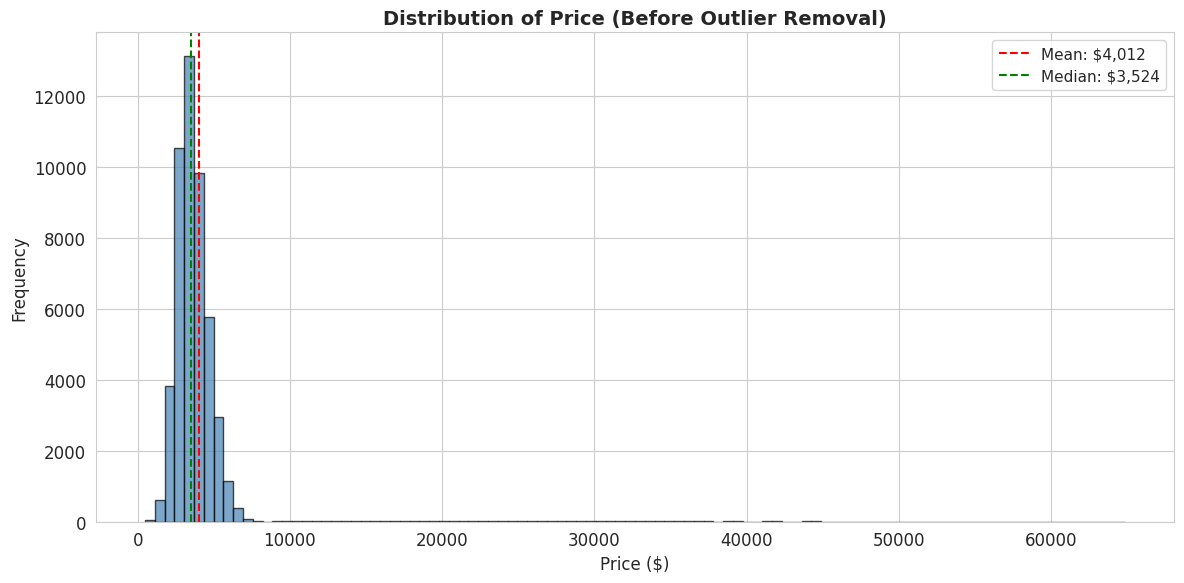

Observation: The distribution is heavily right-skewed due to extreme outliers.
The mean is much higher than the median, indicating the presence of outliers.


In [11]:
# Plot histogram of the target (price)
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(df_subset['price'], bins=100, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_title('Distribution of Price (Before Outlier Removal)', fontsize=14, fontweight='bold')
ax.set_xlabel('Price ($)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.axvline(df_subset['price'].mean(), color='red', linestyle='--', label=f'Mean: ${df_subset["price"].mean():,.0f}')
ax.axvline(df_subset['price'].median(), color='green', linestyle='--', label=f'Median: ${df_subset["price"].median():,.0f}')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('plots/3_2_1_price_histogram_before.png', dpi=150, bbox_inches='tight')
plt.show()

print('Observation: The distribution is heavily right-skewed due to extreme outliers.')
print('The mean is much higher than the median, indicating the presence of outliers.')

### 3.2.2 Target Boxplot

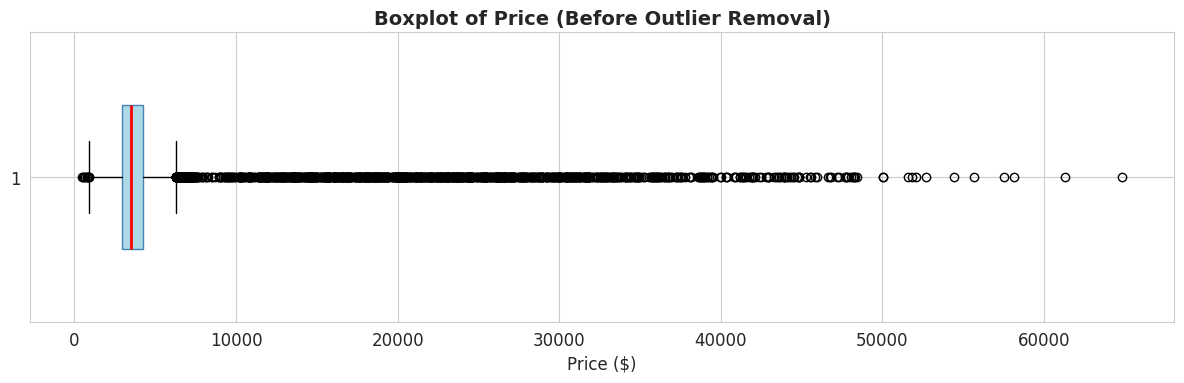

Observation: There are many outliers visible on the right side of the boxplot.
These extreme values distort the distribution significantly.


In [12]:
# Boxplot of price
fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot(df_subset['price'], vert=False, widths=0.5,
           patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='steelblue'),
           medianprops=dict(color='red', linewidth=2))
ax.set_title('Boxplot of Price (Before Outlier Removal)', fontsize=14, fontweight='bold')
ax.set_xlabel('Price ($)', fontsize=12)
plt.tight_layout()
plt.savefig('plots/3_2_2_price_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

print('Observation: There are many outliers visible on the right side of the boxplot.')
print('These extreme values distort the distribution significantly.')

### 3.2.3 Remove Outliers (1st and 99th Percentile)

In [13]:
# Drop rows outside 1st and 99th percentiles
p1 = df_subset['price'].quantile(0.01)
p99 = df_subset['price'].quantile(0.99)
print(f'1st percentile: ${p1:,.0f}')
print(f'99th percentile: ${p99:,.0f}')

rows_before = len(df_subset)
df_subset = df_subset[(df_subset['price'] >= p1) & (df_subset['price'] <= p99)].copy()
rows_after = len(df_subset)
print(f'\nRows before: {rows_before}')
print(f'Rows after: {rows_after}')
print(f'Rows removed: {rows_before - rows_after}')

1st percentile: $1,699
99th percentile: $22,693

Rows before: 49352
Rows after: 48365
Rows removed: 987


### 3.2.4 Histogram After Outlier Removal

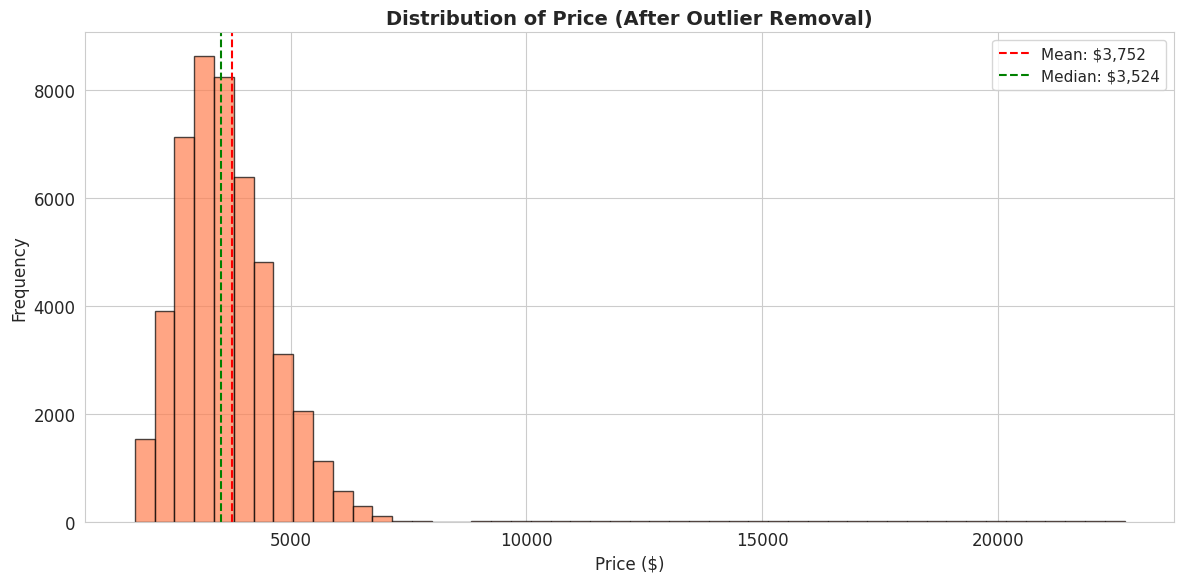

After removing outliers, the distribution is more visible and interpretable.
The distribution still shows a right skew, which is typical for price data.
The mean and median are now closer together.


In [14]:
# Plot histogram after removing outliers
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(df_subset['price'], bins=50, color='coral', edgecolor='black', alpha=0.7)
ax.set_title('Distribution of Price (After Outlier Removal)', fontsize=14, fontweight='bold')
ax.set_xlabel('Price ($)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.axvline(df_subset['price'].mean(), color='red', linestyle='--', label=f'Mean: ${df_subset["price"].mean():,.0f}')
ax.axvline(df_subset['price'].median(), color='green', linestyle='--', label=f'Median: ${df_subset["price"].median():,.0f}')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('plots/3_2_4_price_histogram_after.png', dpi=150, bbox_inches='tight')
plt.show()

print('After removing outliers, the distribution is more visible and interpretable.')
print('The distribution still shows a right skew, which is typical for price data.')
print('The mean and median are now closer together.')

## 3.3 Characteristics Analysis

### 3.3.1 Type of interest_level

In [15]:
# Type of interest_level column
print(f'Data type of interest_level: {df_subset["interest_level"].dtype}')
print(f'\nIt is a categorical (object/string) column.')

Data type of interest_level: str

It is a categorical (object/string) column.


### 3.3.2 Values in interest_level

In [16]:
# Print unique values and their counts
print('Unique values in interest_level:')
print(df_subset['interest_level'].value_counts())
print(f'\nTotal unique values: {df_subset["interest_level"].nunique()}')

Unique values in interest_level:
interest_level
low       34040
medium     9543
high       4782
Name: count, dtype: int64

Total unique values: 3


### 3.3.3 Encode interest_level

In [17]:
# Encode interest_level: low=0, medium=1, high=2
interest_mapping = {'low': 0, 'medium': 1, 'high': 2}
df_subset['interest_level'] = df_subset['interest_level'].map(interest_mapping)

print('Encoding: low=0, medium=1, high=2')
print(f'\nValue counts after encoding:')
print(df_subset['interest_level'].value_counts().sort_index())
df_subset.head()

Encoding: low=0, medium=1, high=2

Value counts after encoding:
interest_level
0    34040
1     9543
2     4782
Name: count, dtype: int64


,bathrooms,bedrooms,interest_level,price
0,0.0,2,0,2944
1,1.5,1,0,2866
2,1.0,1,0,2581
3,2.5,6,0,7198
4,2.5,1,1,3266


### 3.3.4 Feature Histograms

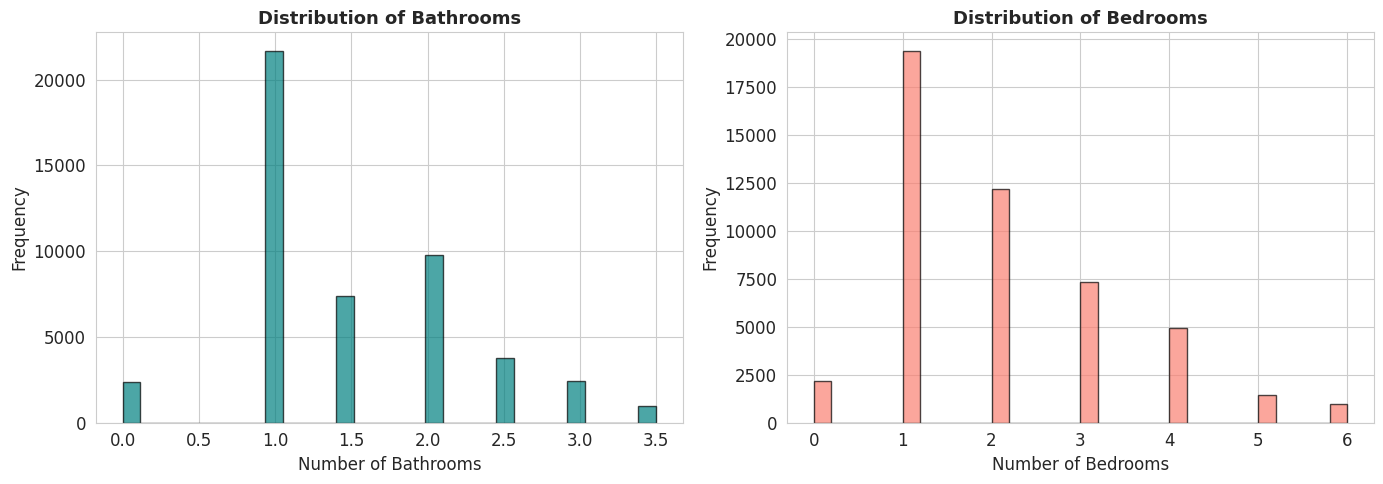

Observations:
• Bathrooms: Most listings have 1 bathroom. Some outliers with high counts.
• Bedrooms: Most listings have 1-2 bedrooms. Some outliers with higher counts.


In [18]:
# Plot histograms for bathrooms and bedrooms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_subset['bathrooms'], bins=30, color='teal', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Bathrooms', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Bathrooms')
axes[0].set_ylabel('Frequency')

axes[1].hist(df_subset['bedrooms'], bins=30, color='salmon', edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution of Bedrooms', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Bedrooms')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('plots/3_3_4_feature_histograms.png', dpi=150, bbox_inches='tight')
plt.show()

print('Observations:')
print('• Bathrooms: Most listings have 1 bathroom. Some outliers with high counts.')
print('• Bedrooms: Most listings have 1-2 bedrooms. Some outliers with higher counts.')

## 3.4 Complex Analysis

### 3.4.1 Correlation Matrix and Heatmap

Correlation Matrix:
                bathrooms  bedrooms  interest_level     price
bathrooms        1.000000 -0.012080        0.005284  0.164164
bedrooms        -0.012080  1.000000        0.002388  0.456096
interest_level   0.005284  0.002388        1.000000 -0.003426
price            0.164164  0.456096       -0.003426  1.000000


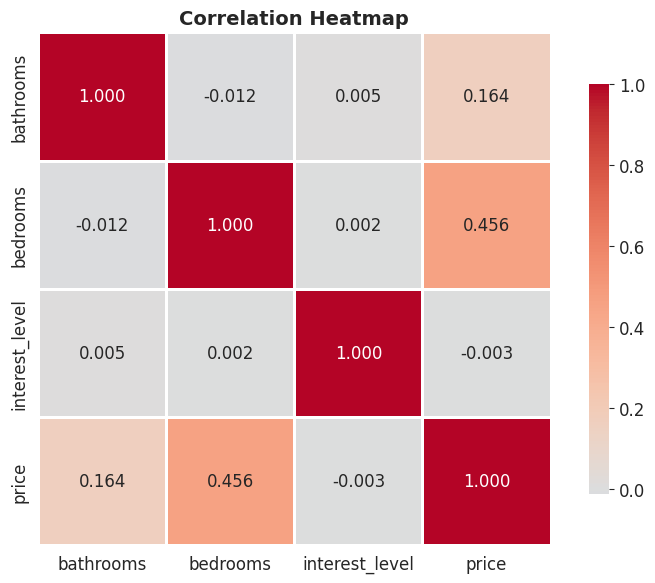


Analysis:
• There is a positive correlation between bedrooms/bathrooms and price.
• Bedrooms and bathrooms are also correlated with each other (expected).
• interest_level shows weak correlation with the price.


In [19]:
# Correlation matrix
corr = df_subset.corr()
print('Correlation Matrix:')
print(corr)

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.3f',
            square=True, linewidths=1, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/3_4_1_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nAnalysis:')
print('• There is a positive correlation between bedrooms/bathrooms and price.')
print('• Bedrooms and bathrooms are also correlated with each other (expected).')
print('• interest_level shows weak correlation with the price.')

### 3.4.2 Scatterplots (Features vs Target)

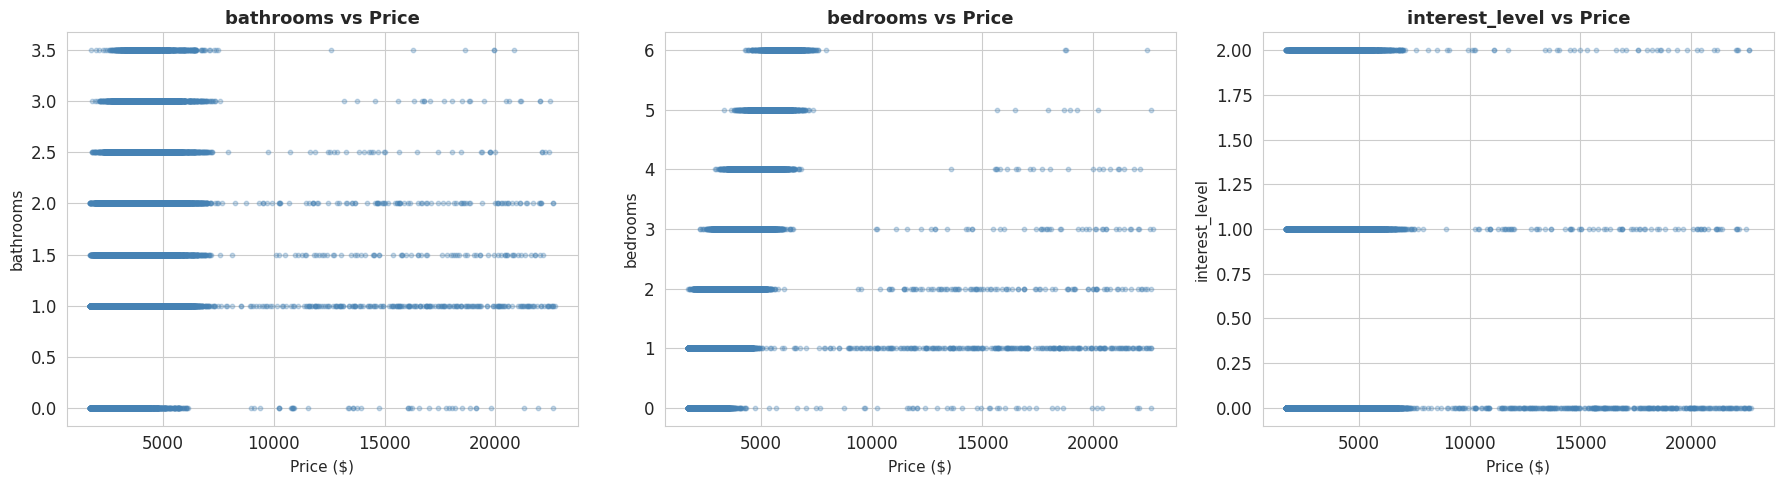

Scatterplots show the relationship between each feature and the target (price).
• Bathrooms vs Price: More bathrooms tends to correlate with higher prices.
• Bedrooms vs Price: More bedrooms tends to correlate with higher prices.
• Interest Level vs Price: No clear linear relationship.


In [20]:
# Scatterplots: Features vs Price
features_to_plot = ['bathrooms', 'bedrooms', 'interest_level']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features_to_plot):
    axes[i].scatter(df_subset['price'], df_subset[feature], alpha=0.3, s=10, color='steelblue')
    axes[i].set_xlabel('Price ($)', fontsize=11)
    axes[i].set_ylabel(feature, fontsize=11)
    axes[i].set_title(f'{feature} vs Price', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/3_4_2_scatterplots.png', dpi=150, bbox_inches='tight')
plt.show()

print('Scatterplots show the relationship between each feature and the target (price).')
print('• Bathrooms vs Price: More bathrooms tends to correlate with higher prices.')
print('• Bedrooms vs Price: More bedrooms tends to correlate with higher prices.')
print('• Interest Level vs Price: No clear linear relationship.')

---
# 4. Creating Features

## 4.1 Squared Features and Correlation

Correlation with Price:
price                     1.000000
bedrooms                  0.456096
bedrooms_squared          0.442377
bathrooms                 0.164164
bathrooms_squared         0.158718
interest_level           -0.003426
interest_level_squared   -0.003657
Name: price, dtype: float64


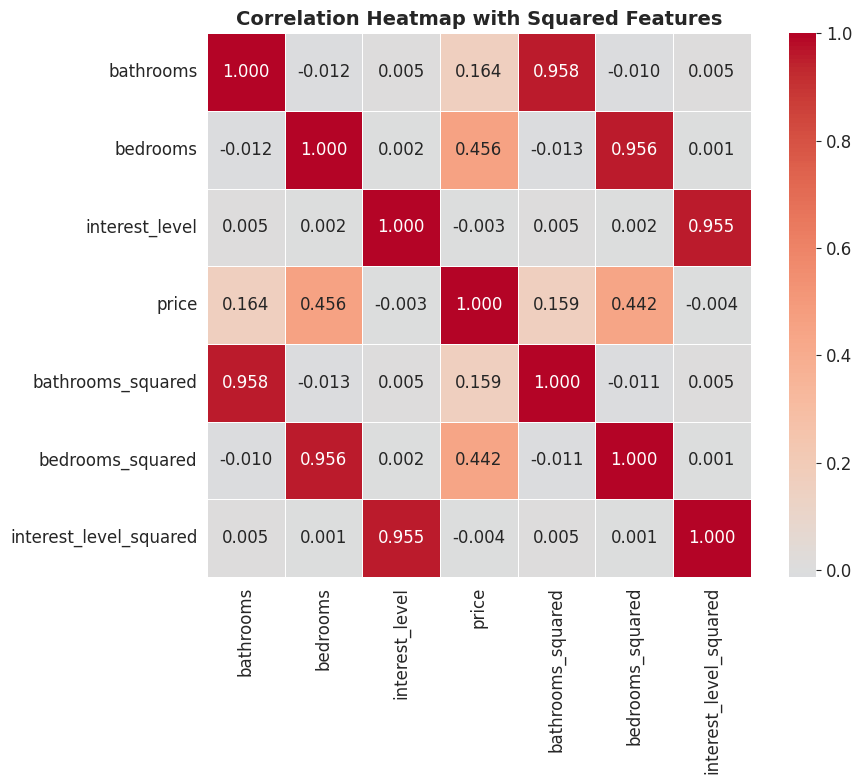


Analysis: The squared features show similar or slightly different correlation
patterns compared to the original features. Squared features can capture
non-linear relationships between features and the target.


In [21]:
# Create squared features
df_features = df_subset.copy()
df_features['bathrooms_squared'] = df_features['bathrooms'] ** 2
df_features['bedrooms_squared'] = df_features['bedrooms'] ** 2
df_features['interest_level_squared'] = df_features['interest_level'] ** 2

# Correlation matrix with new features
corr_new = df_features.corr()
print('Correlation with Price:')
print(corr_new['price'].sort_values(ascending=False))

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_new, annot=True, cmap='coolwarm', center=0, fmt='.3f',
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap with Squared Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/4_1_correlation_squared.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nAnalysis: The squared features show similar or slightly different correlation')
print('patterns compared to the original features. Squared features can capture')
print('non-linear relationships between features and the target.')

## 4.2 Features for Model Training

For model training, we will only use **'bathrooms'** and **'bedrooms'** as features.
The squared and other engineered features can be explored in Lecture 2.

## 4.3-4.4 Train/Test Split

In [22]:
# Prepare data for modeling
# Features: bathrooms, bedrooms
# Target: price

X = df_subset[['bathrooms', 'bedrooms']].values
y = df_subset['price'].values

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set: {X_test.shape[0]} samples')
print(f'Features: bathrooms, bedrooms')
print(f'Target: price')

Training set: 38692 samples
Test set: 9673 samples
Features: bathrooms, bedrooms
Target: price


## 4.5-4.6 PolynomialFeatures (Degree 10)

In [23]:
# Initialize PolynomialFeatures with degree=10
poly = PolynomialFeatures(degree=10)

# Fit and transform training data
X_train_poly = poly.fit_transform(X_train)
# Transform test data
X_test_poly = poly.transform(X_test)

print(f'Original features: {X_train.shape[1]}')
print(f'Polynomial features: {X_train_poly.shape[1]}')
print(f'\nPolynomialFeatures expands 2 features into {X_train_poly.shape[1]} features')
print(f'using combinations up to degree 10.')
print(f'\nFeature names (first 15):')
feature_names = poly.get_feature_names_out(['bathrooms', 'bedrooms'])
for name in feature_names[:15]:
    print(f'  • {name}')
print(f'  ... and {len(feature_names) - 15} more')

Original features: 2
Polynomial features: 66

PolynomialFeatures expands 2 features into 66 features
using combinations up to degree 10.

Feature names (first 15):
  • 1
  • bathrooms
  • bedrooms
  • bathrooms^2
  • bathrooms bedrooms
  • bedrooms^2
  • bathrooms^3
  • bathrooms^2 bedrooms
  • bathrooms bedrooms^2
  • bedrooms^3
  • bathrooms^4
  • bathrooms^3 bedrooms
  • bathrooms^2 bedrooms^2
  • bathrooms bedrooms^3
  • bedrooms^4
  ... and 51 more


---
# 5. Model Training and Comparison

## 5.1 Results Tables

In [24]:
# Create empty results DataFrames
result_MAE = pd.DataFrame(columns=['model', 'train', 'test'])
result_RMSE = pd.DataFrame(columns=['model', 'train', 'test'])

print('Empty result tables created.')
print('result_MAE:', result_MAE.shape)
print('result_RMSE:', result_RMSE.shape)

Empty result tables created.
result_MAE: (0, 3)
result_RMSE: (0, 3)


## 5.2 Linear Regression

In [25]:
# Initialize and train Linear Regression
lr = LinearRegression()
lr.fit(X_train_poly, y_train)

# Predictions
y_train_pred_lr = lr.predict(X_train_poly)
y_test_pred_lr = lr.predict(X_test_poly)

# MAE
mae_train_lr = mean_absolute_error(y_train, y_train_pred_lr)
mae_test_lr = mean_absolute_error(y_test, y_test_pred_lr)

# RMSE
rmse_train_lr = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))
rmse_test_lr = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))

# Insert into result tables
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'linear_regression',
    'train': round(mae_train_lr, 2),
    'test': round(mae_test_lr, 2)
}])], ignore_index=True)

result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'linear_regression',
    'train': round(rmse_train_lr, 2),
    'test': round(rmse_test_lr, 2)
}])], ignore_index=True)

print('=== Linear Regression Results ===')
print(f'MAE  - Train: {mae_train_lr:.2f}, Test: {mae_test_lr:.2f}')
print(f'RMSE - Train: {rmse_train_lr:.2f}, Test: {rmse_test_lr:.2f}')

=== Linear Regression Results ===
MAE  - Train: 524.30, Test: 537.61
RMSE - Train: 1378.50, Test: 1464.52


## 5.3 Decision Tree

In [26]:
# Initialize and train Decision Tree Regressor
dt = DecisionTreeRegressor(random_state=21)
dt.fit(X_train_poly, y_train)

# Predictions
y_train_pred_dt = dt.predict(X_train_poly)
y_test_pred_dt = dt.predict(X_test_poly)

# MAE
mae_train_dt = mean_absolute_error(y_train, y_train_pred_dt)
mae_test_dt = mean_absolute_error(y_test, y_test_pred_dt)

# RMSE
rmse_train_dt = np.sqrt(mean_squared_error(y_train, y_train_pred_dt))
rmse_test_dt = np.sqrt(mean_squared_error(y_test, y_test_pred_dt))

# Insert into result tables
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'decision_tree',
    'train': round(mae_train_dt, 2),
    'test': round(mae_test_dt, 2)
}])], ignore_index=True)

result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'decision_tree',
    'train': round(rmse_train_dt, 2),
    'test': round(rmse_test_dt, 2)
}])], ignore_index=True)

print('=== Decision Tree Results ===')
print(f'MAE  - Train: {mae_train_dt:.2f}, Test: {mae_test_dt:.2f}')
print(f'RMSE - Train: {rmse_train_dt:.2f}, Test: {rmse_test_dt:.2f}')

=== Decision Tree Results ===
MAE  - Train: 524.31, Test: 537.64
RMSE - Train: 1378.50, Test: 1464.50


## 5.4 Naive Models

In [27]:
# Naive Model: Mean
mean_train = y_train.mean()
mean_test = y_test.mean()

y_train_pred_mean = np.full_like(y_train, fill_value=mean_train, dtype=float)
y_test_pred_mean = np.full_like(y_test, fill_value=mean_train, dtype=float)

# MAE for naive mean
mae_train_mean = mean_absolute_error(y_train, y_train_pred_mean)
mae_test_mean = mean_absolute_error(y_test, y_test_pred_mean)

# RMSE for naive mean
rmse_train_mean = np.sqrt(mean_squared_error(y_train, y_train_pred_mean))
rmse_test_mean = np.sqrt(mean_squared_error(y_test, y_test_pred_mean))

# Naive Model: Median
median_train = np.median(y_train)

y_train_pred_median = np.full_like(y_train, fill_value=median_train, dtype=float)
y_test_pred_median = np.full_like(y_test, fill_value=median_train, dtype=float)

# MAE for naive median
mae_train_median = mean_absolute_error(y_train, y_train_pred_median)
mae_test_median = mean_absolute_error(y_test, y_test_pred_median)

# RMSE for naive median
rmse_train_median = np.sqrt(mean_squared_error(y_train, y_train_pred_median))
rmse_test_median = np.sqrt(mean_squared_error(y_test, y_test_pred_median))

# Insert naive mean into results
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'naive_mean',
    'train': round(mae_train_mean, 2),
    'test': round(mae_test_mean, 2)
}])], ignore_index=True)

result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'naive_mean',
    'train': round(rmse_train_mean, 2),
    'test': round(rmse_test_mean, 2)
}])], ignore_index=True)

# Insert naive median into results
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'naive_median',
    'train': round(mae_train_median, 2),
    'test': round(mae_test_median, 2)
}])], ignore_index=True)

result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'naive_median',
    'train': round(rmse_train_median, 2),
    'test': round(rmse_test_median, 2)
}])], ignore_index=True)

print('=== Naive Mean Results ===')
print(f'Mean value used: {mean_train:.2f}')
print(f'MAE  - Train: {mae_train_mean:.2f}, Test: {mae_test_mean:.2f}')
print(f'RMSE - Train: {rmse_train_mean:.2f}, Test: {rmse_test_mean:.2f}')

print('\n=== Naive Median Results ===')
print(f'Median value used: {median_train:.2f}')
print(f'MAE  - Train: {mae_train_median:.2f}, Test: {mae_test_median:.2f}')
print(f'RMSE - Train: {rmse_train_median:.2f}, Test: {rmse_test_median:.2f}')

=== Naive Mean Results ===
Mean value used: 3748.55
MAE  - Train: 895.14, Test: 902.66
RMSE - Train: 1588.10, Test: 1642.68

=== Naive Median Results ===
Median value used: 3524.50
MAE  - Train: 874.48, Test: 881.58
RMSE - Train: 1603.83, Test: 1660.48


## 5.5 Compare Results

In [28]:
# Print final results tables
print('=' * 60)
print('FINAL RESULTS: Mean Absolute Error (MAE)')
print('=' * 60)
print(result_MAE.to_string(index=False))

print('\n' + '=' * 60)
print('FINAL RESULTS: Root Mean Square Error (RMSE)')
print('=' * 60)
print(result_RMSE.to_string(index=False))

print('\n--- Analysis ---')
# Find best model by test MAE
best_mae_idx = result_MAE['test'].astype(float).idxmin()
best_rmse_idx = result_RMSE['test'].astype(float).idxmin()

print(f'Best model by test MAE: {result_MAE.loc[best_mae_idx, "model"]} '
      f'(MAE = {result_MAE.loc[best_mae_idx, "test"]})')
print(f'Best model by test RMSE: {result_RMSE.loc[best_rmse_idx, "model"]} '
      f'(RMSE = {result_RMSE.loc[best_rmse_idx, "test"]})')

print('\nConclusion:')
print('• Linear Regression with PolynomialFeatures degree=10 performs better than naive models.')
print('• Decision Tree may overfit the training data (low train error, high test error).')
print('• Naive models serve as baselines — any good model should beat them.')
print('• The best model is the one with the lowest test error (generalization).')

FINAL RESULTS: Mean Absolute Error (MAE)
            model   train    test
linear_regression   524.3  537.61
    decision_tree  524.31  537.64
       naive_mean  895.14  902.66
     naive_median  874.48  881.58

FINAL RESULTS: Root Mean Square Error (RMSE)
            model    train     test
linear_regression   1378.5  1464.52
    decision_tree   1378.5   1464.5
       naive_mean   1588.1  1642.68
     naive_median  1603.83  1660.48

--- Analysis ---
Best model by test MAE: linear_regression (MAE = 537.61)
Best model by test RMSE: decision_tree (RMSE = 1464.5)

Conclusion:
• Linear Regression with PolynomialFeatures degree=10 performs better than naive models.
• Decision Tree may overfit the training data (low train error, high test error).
• Naive models serve as baselines — any good model should beat them.
• The best model is the one with the lowest test error (generalization).


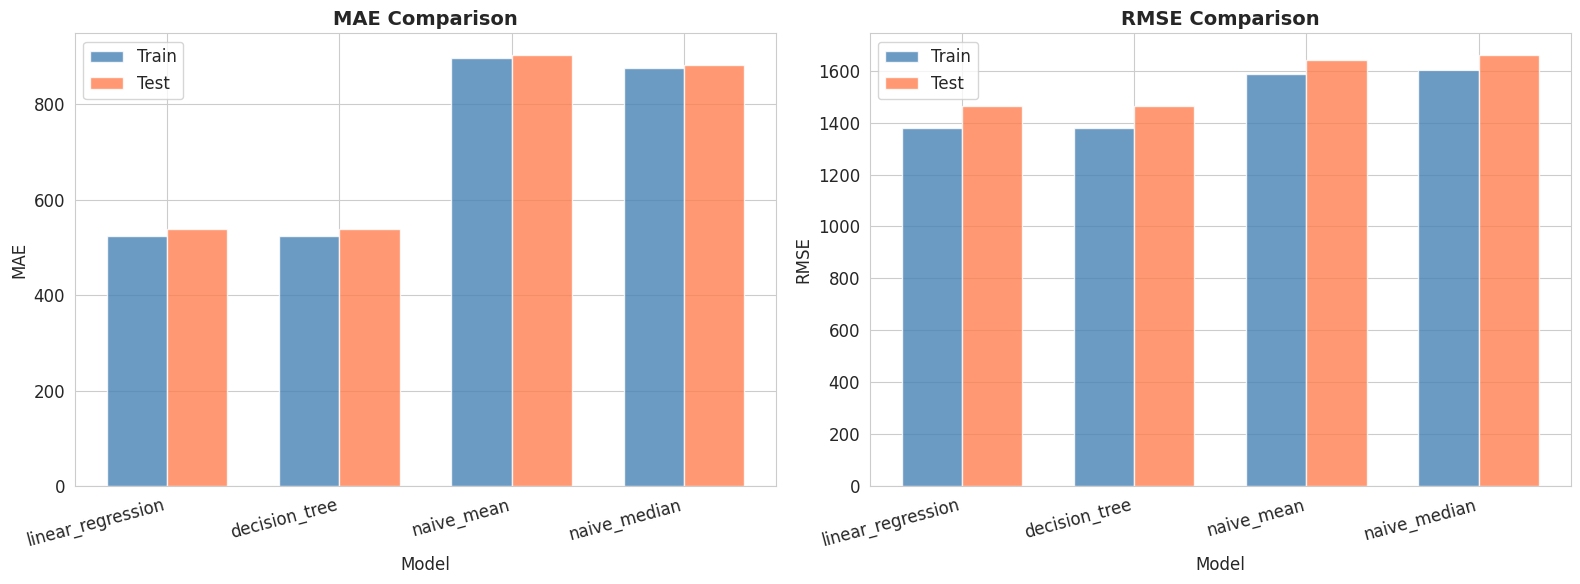

In [29]:
# Visualize model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# MAE comparison
x_pos = range(len(result_MAE))
width = 0.35
axes[0].bar([p - width/2 for p in x_pos], result_MAE['train'].astype(float), width,
            label='Train', color='steelblue', alpha=0.8)
axes[0].bar([p + width/2 for p in x_pos], result_MAE['test'].astype(float), width,
            label='Test', color='coral', alpha=0.8)
axes[0].set_xlabel('Model')
axes[0].set_ylabel('MAE')
axes[0].set_title('MAE Comparison', fontsize=14, fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(result_MAE['model'], rotation=15, ha='right')
axes[0].legend()

# RMSE comparison
axes[1].bar([p - width/2 for p in x_pos], result_RMSE['train'].astype(float), width,
            label='Train', color='steelblue', alpha=0.8)
axes[1].bar([p + width/2 for p in x_pos], result_RMSE['test'].astype(float), width,
            label='Test', color='coral', alpha=0.8)
axes[1].set_xlabel('Model')
axes[1].set_ylabel('RMSE')
axes[1].set_title('RMSE Comparison', fontsize=14, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(result_RMSE['model'], rotation=15, ha='right')
axes[1].legend()

plt.tight_layout()
plt.savefig('plots/5_5_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Summary

In this notebook we covered:

1. **Introduction**: ML examples, task classification, multiclass vs multilabel, regression vs classification
2. **Data Analysis**: Loaded the Two Sigma rental dataset, explored its structure, created a 4-column subset
3. **Statistical Analysis**: Analyzed price distribution, removed outliers, encoded categorical features, plotted correlations
4. **Feature Engineering**: Created squared features, applied PolynomialFeatures (degree=10)
5. **Model Training**: Trained Linear Regression, Decision Tree, and Naive models; compared using MAE and RMSE

The key takeaway is that even simple ML models can outperform naive baselines, and proper data preprocessing (outlier removal, feature engineering) is essential for model performance.